In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor


In [2]:
df = pd.read_csv("dataset_academic.csv")

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (80000, 31)


,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98


In [3]:
df["screen_time_total"] = (
    df["social_media_hours"] +
    df["netflix_hours"] +
    df["screen_time"]
)

df["study_sleep_ratio"] = df["study_hours_per_day"] / df["sleep_hours"]

df["stress_anxiety"] = (
    df["stress_level"] + df["exam_anxiety_score"]
)


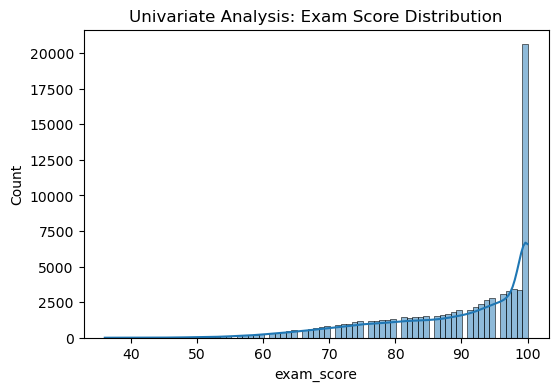

In [4]:
plt.figure(figsize=(6,4))
sns.histplot(df["exam_score"], kde=True)
plt.title("Univariate Analysis: Exam Score Distribution")
plt.show()


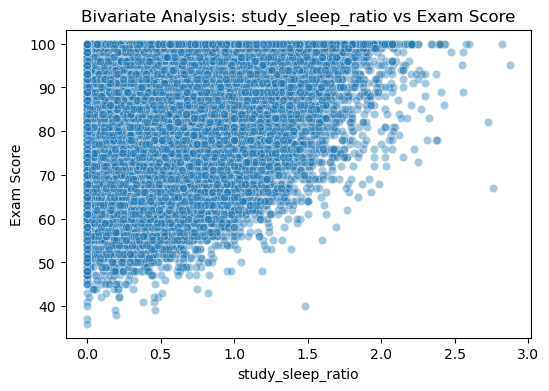

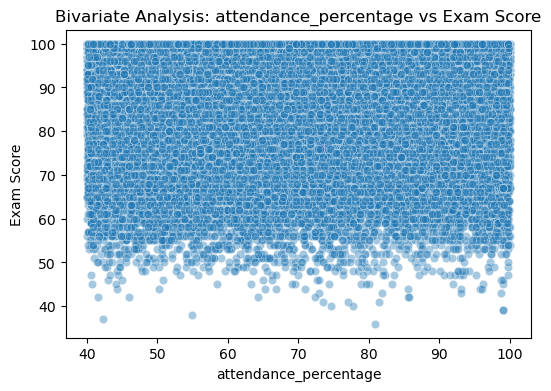

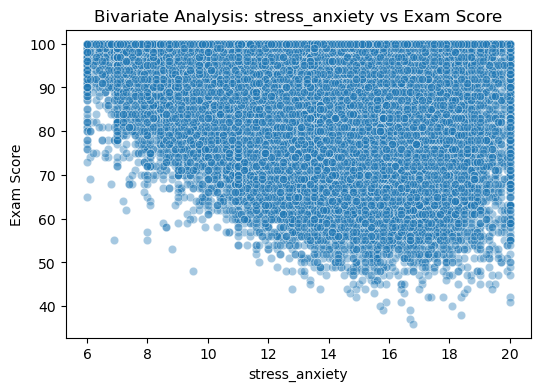

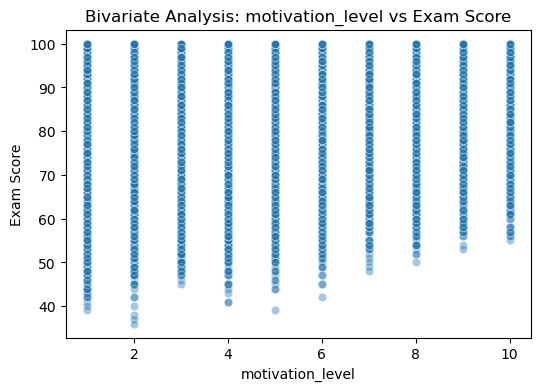

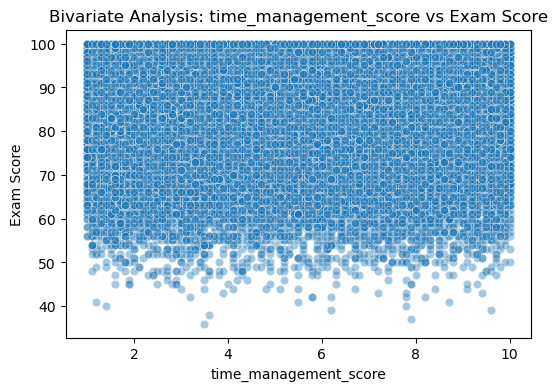

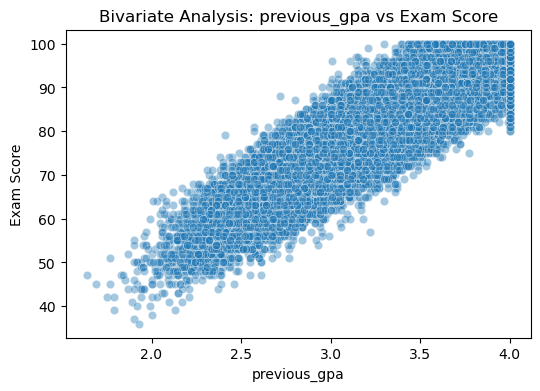

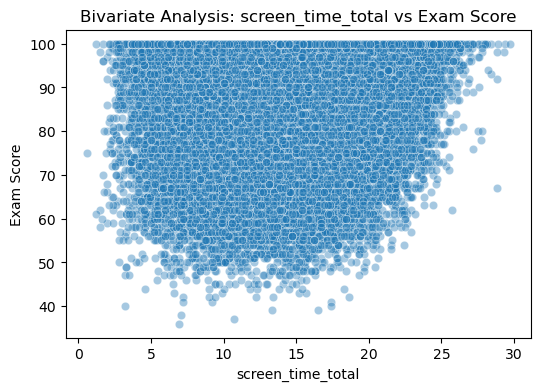

In [5]:
num_features = [
    "study_sleep_ratio",
    "attendance_percentage",
    "stress_anxiety",
    "motivation_level",
    "time_management_score",
    "previous_gpa",
    "screen_time_total"
]


for col in num_features:
    plt.figure(figsize=(6,4))
    sns.scatterplot(data=df, x=col, y="exam_score", alpha=0.4)
    plt.title(f"Bivariate Analysis: {col} vs Exam Score")
    plt.xlabel(col)
    plt.ylabel("Exam Score")
    plt.show()


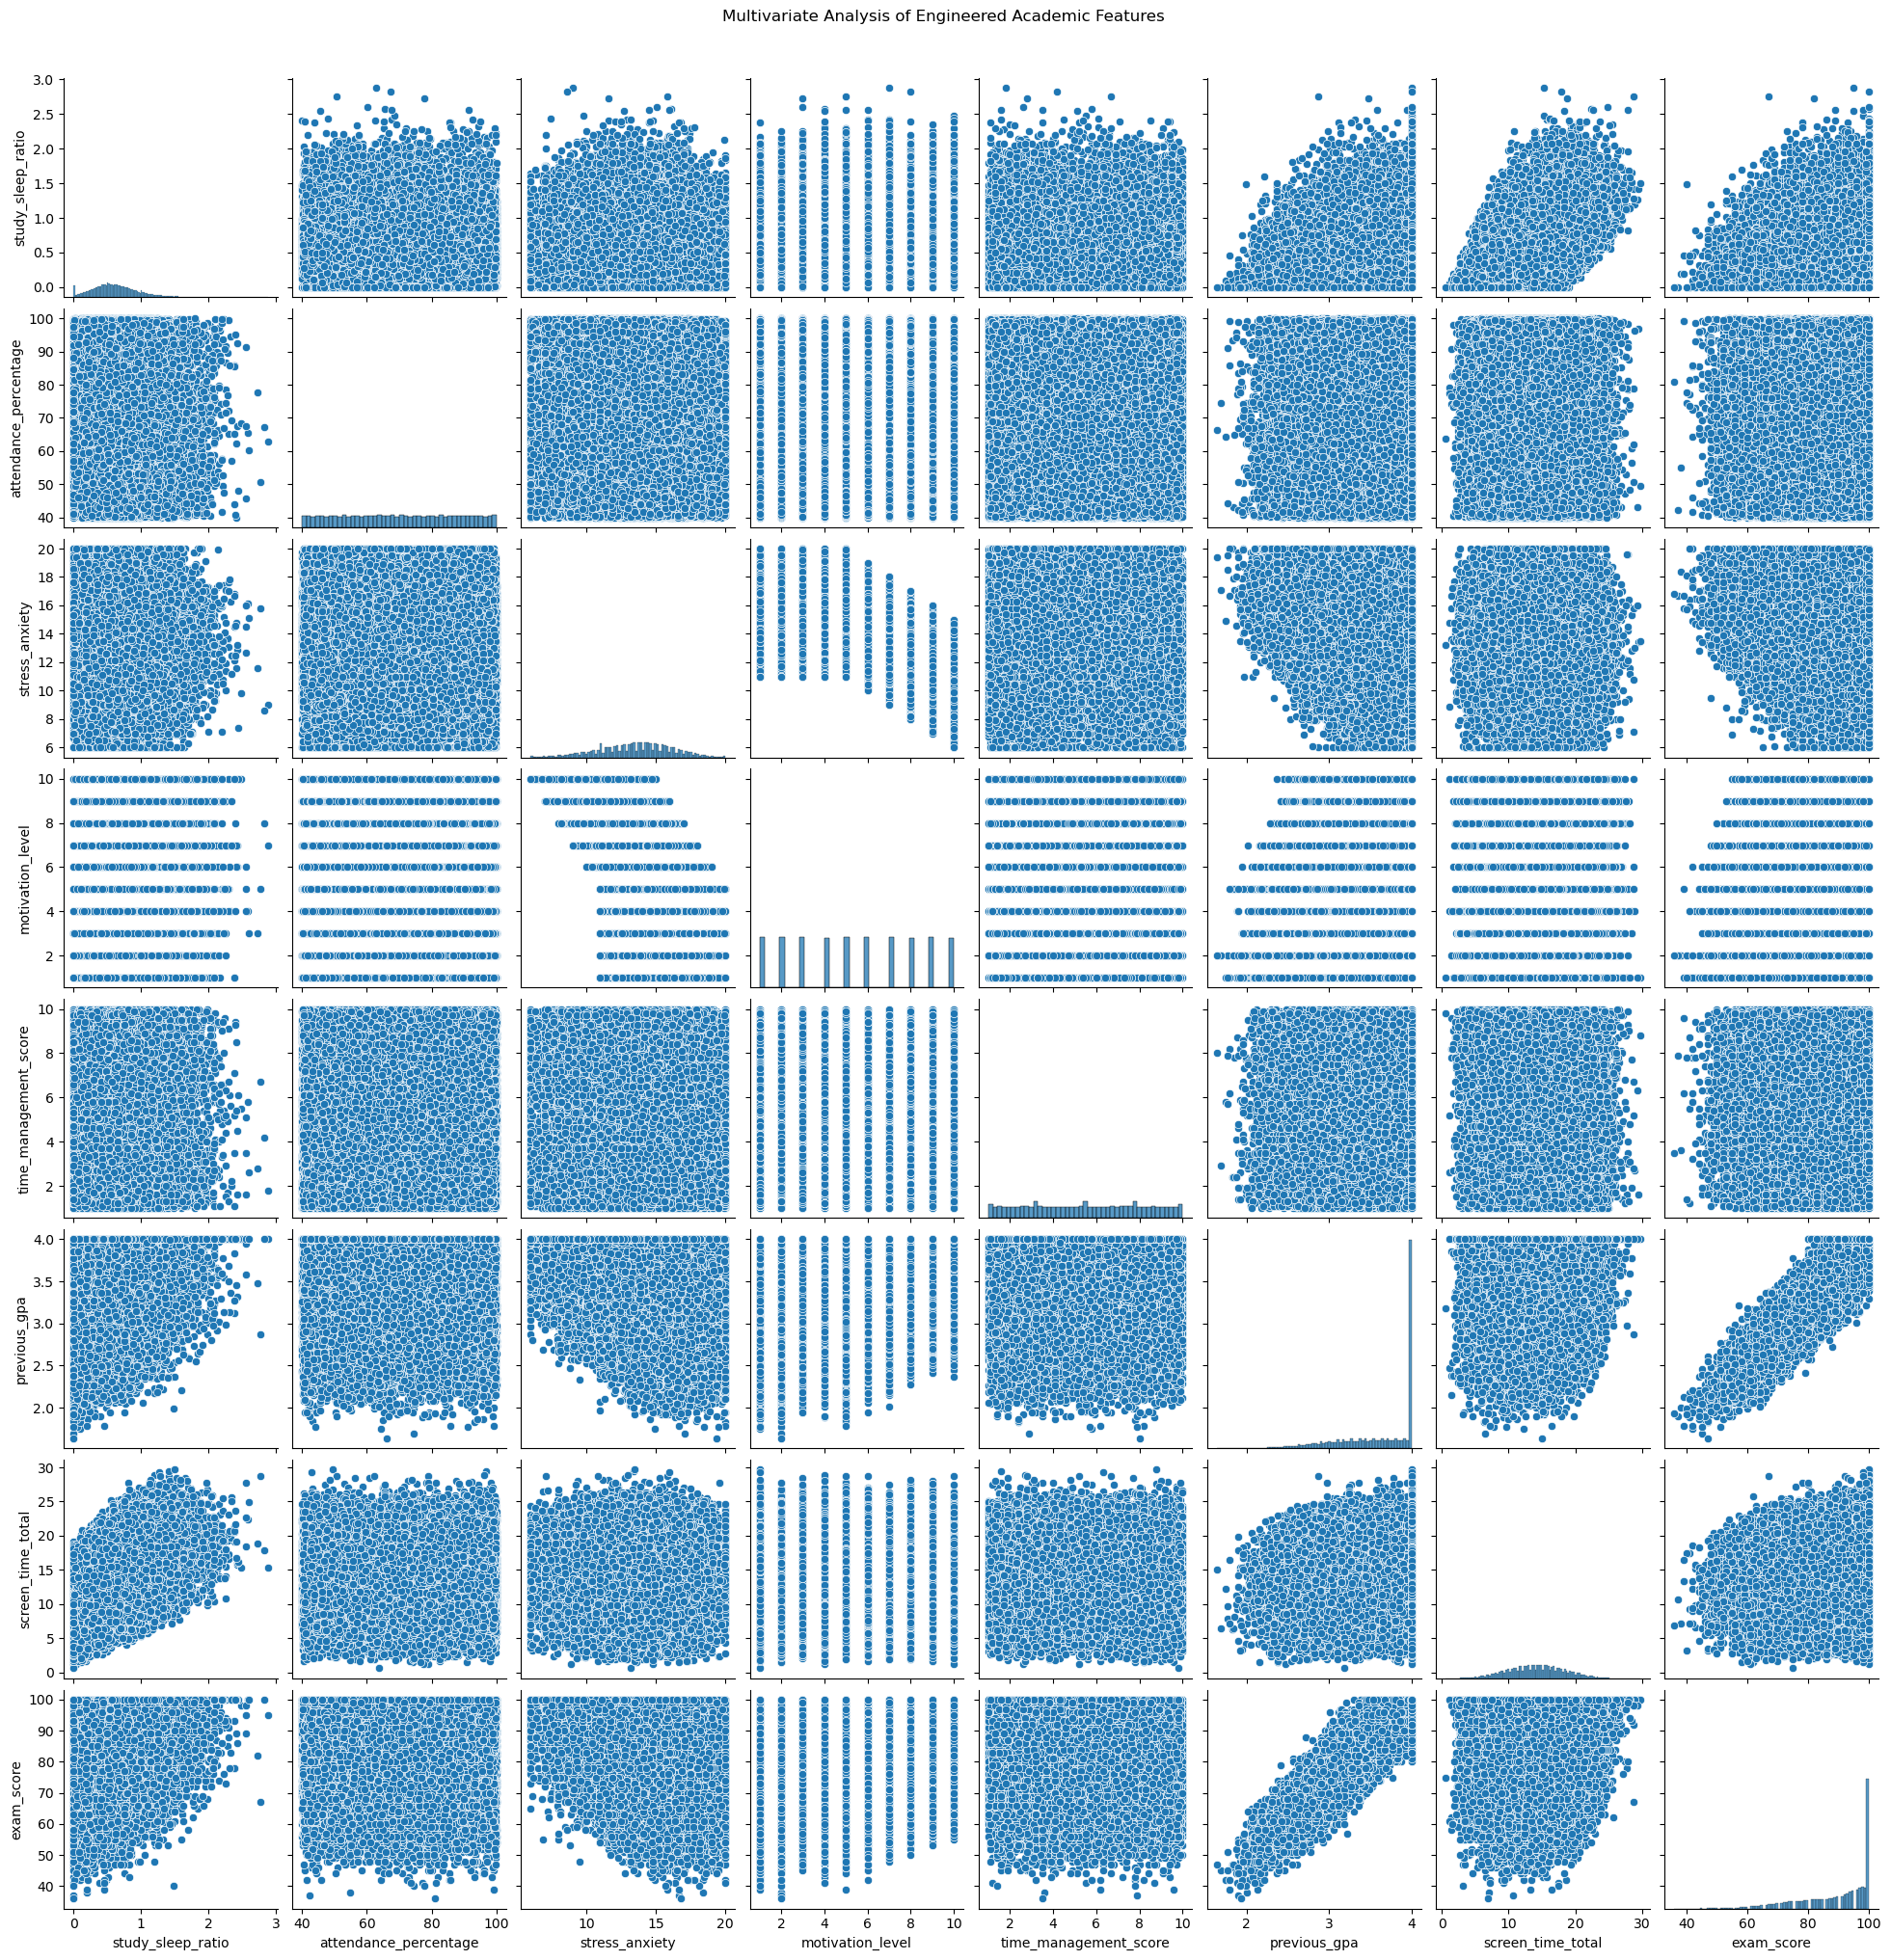

In [6]:
multivariate_features = num_features + ["exam_score"]

sns.pairplot(df[multivariate_features])
plt.suptitle(
    "Multivariate Analysis of Engineered Academic Features",
    y=1.02
)
plt.show()


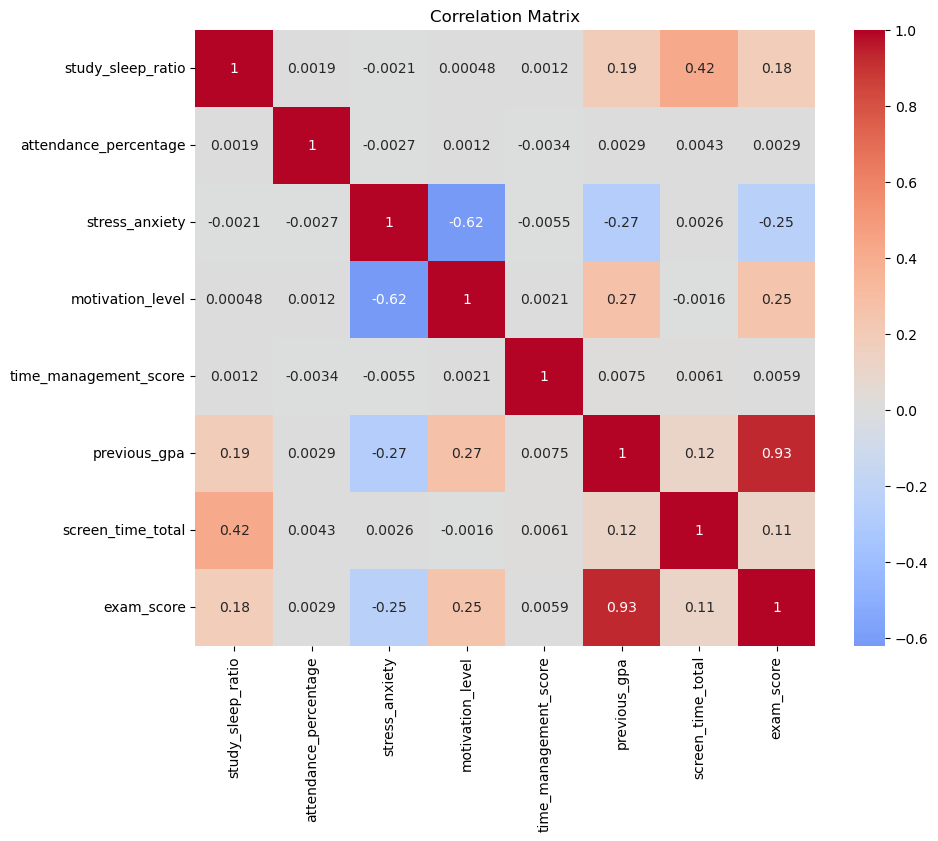

exam_score               1.000000
previous_gpa             0.932940
motivation_level         0.250287
study_sleep_ratio        0.179761
screen_time_total        0.109008
time_management_score    0.005940
attendance_percentage    0.002876
stress_anxiety          -0.247111
Name: exam_score, dtype: float64


In [7]:
numeric_df = df[multivariate_features]

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

corr_target = corr_matrix["exam_score"].sort_values(ascending=False)
print(corr_target)


In [8]:
TOP_K = 7
TARGET = "exam_score"   # numerical target

# =========================
# 🔢 NUMERICAL FEATURES
# =========================

# Correlation of all numerical features with target
num_corr_series = (
    corr_target
    .drop(TARGET)      # remove target itself
    .abs()
    .sort_values(ascending=False)
)

# Convert to DataFrame for clean printing
num_corr_df = (
    num_corr_series
    .to_frame(name="Absolute_Correlation")
)

print("\nCorrelation values for ALL numerical features:")
print(num_corr_df)

# Select Top-K numerical features
top_numerical_features = num_corr_df.head(TOP_K).index.tolist()

print(f"\nTop {TOP_K} Numerical Features based on Correlation:")
print(top_numerical_features)



Correlation values for ALL numerical features:
                       Absolute_Correlation
previous_gpa                       0.932940
motivation_level                   0.250287
stress_anxiety                     0.247111
study_sleep_ratio                  0.179761
screen_time_total                  0.109008
time_management_score              0.005940
attendance_percentage              0.002876

Top 7 Numerical Features based on Correlation:
['previous_gpa', 'motivation_level', 'stress_anxiety', 'study_sleep_ratio', 'screen_time_total', 'time_management_score', 'attendance_percentage']


In [9]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

TOP_K = 4
CAT_THRESHOLD = 0.002
TARGET = "dropout_risk"

# =========================
# 🏷️ CATEGORICAL FEATURES
# =========================

# Identify categorical columns (excluding target)
categorical_cols_all = df.select_dtypes(include='object').columns.tolist()
categorical_cols_all.remove(TARGET)

# Cramér’s V function
def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Compute Cramér’s V for all categorical features
cat_corr_results = {}

for col in categorical_cols_all:
    contingency = pd.crosstab(df[col], df[TARGET])
    cat_corr_results[col] = cramers_v(contingency.to_numpy())

# Convert to DataFrame for clean printing
cat_corr_df = (
    pd.DataFrame.from_dict(cat_corr_results, orient='index', columns=['Cramers_V'])
    .sort_values(by='Cramers_V', ascending=False)
)

print("\nCramér’s V values for ALL categorical features:")
print(cat_corr_df)

print("\nCramér’s V Threshold Used:")
print(CAT_THRESHOLD)

# =========================
# ✅ Apply Threshold + Top-K
# =========================

filtered_cat_features = cat_corr_df[cat_corr_df['Cramers_V'] >= CAT_THRESHOLD]
important_categorical_features = filtered_cat_features.head(TOP_K).index.tolist()

print("\nSelected Categorical Features after Thresholding and Top-K:")
print(important_categorical_features )



Cramér’s V values for ALL categorical features:
                               Cramers_V
parental_education_level        0.010713
major                           0.010125
study_environment               0.008175
diet_quality                    0.007581
gender                          0.005340
family_income_range             0.003891
learning_style                  0.003782
internet_quality                0.002904
extracurricular_participation   0.002039
part_time_job                   0.001911
access_to_tutoring              0.000490

Cramér’s V Threshold Used:
0.002

Selected Categorical Features after Thresholding and Top-K:
['parental_education_level', 'major', 'study_environment', 'diet_quality']


In [10]:
selected_features = top_numerical_features + important_categorical_features

print("\nFinal Selected Features for Modeling:")
print(selected_features)



Final Selected Features for Modeling:
['previous_gpa', 'motivation_level', 'stress_anxiety', 'study_sleep_ratio', 'screen_time_total', 'time_management_score', 'attendance_percentage', 'parental_education_level', 'major', 'study_environment', 'diet_quality']


In [11]:
X = df[selected_features]
y = df["exam_score"]


In [12]:
categorical_cols = X.select_dtypes(include="object").columns
numerical_cols = X.select_dtypes(include=np.number).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)
])


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [14]:
from sklearn.ensemble import StackingRegressor

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        eval_metric="rmse"  # required for latest XGB
    ),
    "SVR": SVR(kernel="rbf"),
    "Hybrid (RF + XGB)": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(n_estimators=150, random_state=42)),
            ("xgb_base", XGBRegressor(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=5,
                random_state=42,
                eval_metric="rmse"
            ))
        ],
        final_estimator=XGBRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=4,
            random_state=42,
            eval_metric="rmse"
        ),
        passthrough=False  # ⚡ Faster training
    )
}


In [15]:
results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

    print(f"⏳ Training {name}...")
    pipeline.fit(X_train, y_train)

    preds = pipeline.predict(X_test)

    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)

    # Store all metrics in results
    results[name] = {
        "pipeline": pipeline,
        "r2": r2,
        "rmse": rmse,
        "mae": mae
    }

    print(f"✔ {name} → R²: {r2:.4f}, RMSE: {rmse:.2f}, MAE: {mae:.2f}")


⏳ Training Random Forest...
✔ Random Forest → R²: 0.8680, RMSE: 4.23, MAE: 3.30
⏳ Training XGBoost...
✔ XGBoost → R²: 0.8707, RMSE: 4.18, MAE: 3.24
⏳ Training SVR...
✔ SVR → R²: 0.8627, RMSE: 4.31, MAE: 3.14
⏳ Training Hybrid (RF + XGB)...
✔ Hybrid (RF + XGB) → R²: 0.8715, RMSE: 4.17, MAE: 3.24


In [16]:
results_df = pd.DataFrame(results).T.drop(columns=["pipeline"])
print("\n📊 Final Model Performance Comparison:\n")
print(results_df)



📊 Final Model Performance Comparison:

                         r2      rmse       mae
Random Forest      0.868011  4.227259  3.299288
XGBoost            0.870748  4.183206  3.235497
SVR                 0.86268  4.311796  3.135804
Hybrid (RF + XGB)  0.871494  4.171125  3.235844


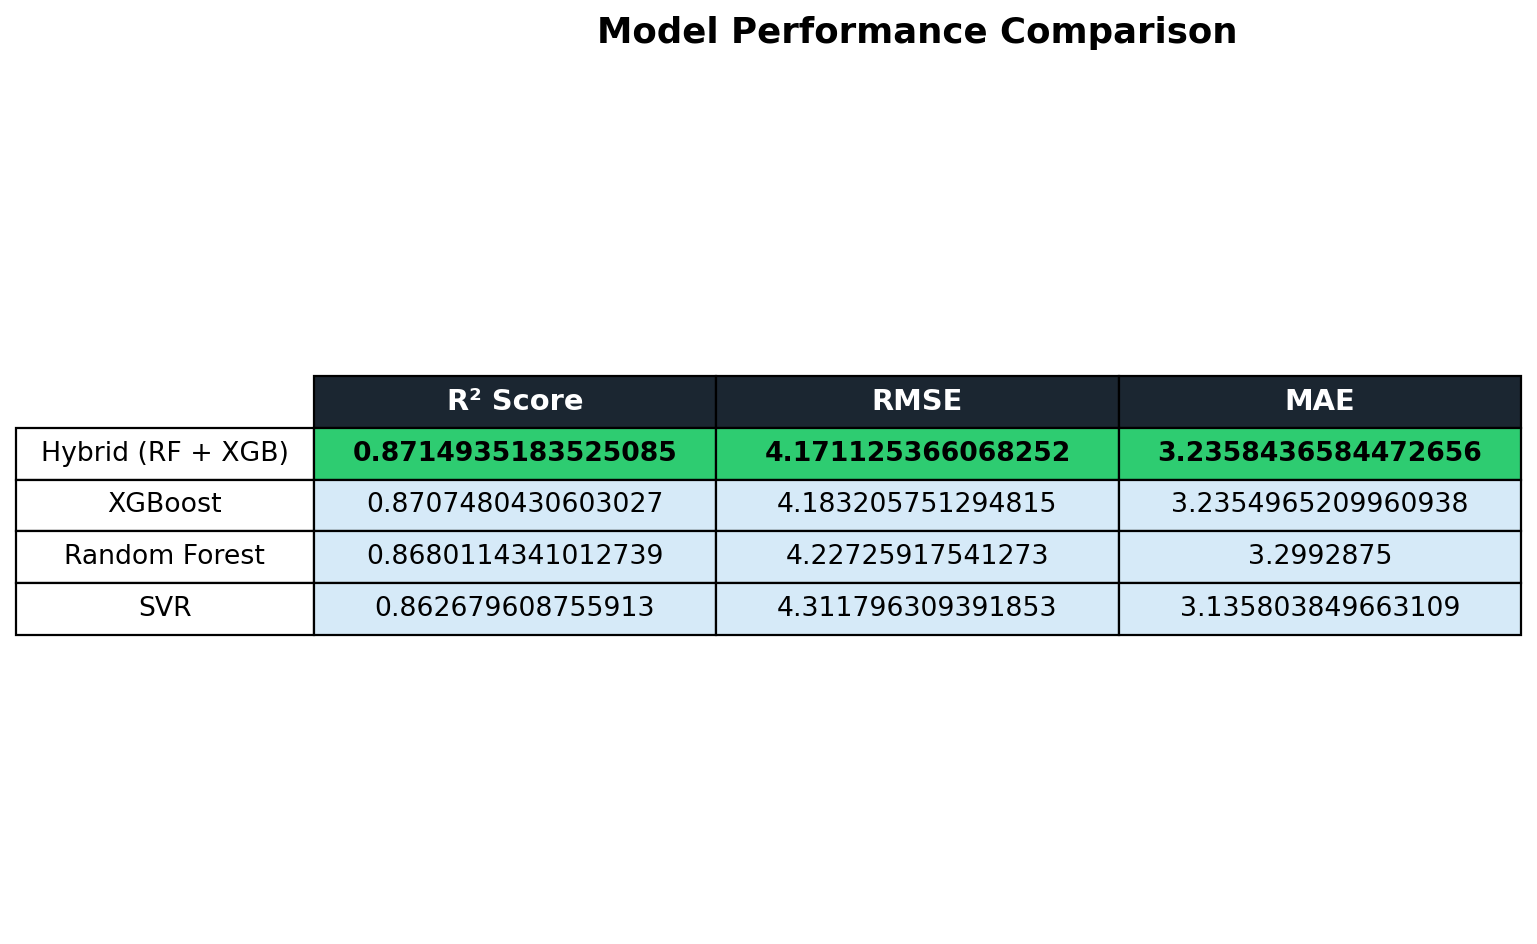

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare Data
results_df = pd.DataFrame(results).T.drop(columns=["pipeline"])
results_df.rename(columns={"r2": "R² Score", "rmse": "RMSE", "mae": "MAE"}, inplace=True)
results_df = results_df.sort_values(by="R² Score", ascending=False)
results_df = results_df.round(4)

# Table Formatting
plt.figure(figsize=(10, 2 + len(results_df)), dpi=160)
plt.title("Model Performance Comparison", fontsize=16, fontweight='bold', pad=18)

# Define colors
header_color = "#1B2631"
best_color = "#2ECC71"
normal_color = "#D6EAF8"
text_color = "black"

# Draw Table
table = plt.table(
    cellText=results_df.values,
    rowLabels=results_df.index,
    colLabels=results_df.columns,
    cellLoc='center',
    rowLoc='center',
    loc='center'
)

# Styling
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.7)

# Header styling
for col in range(len(results_df.columns)):
    cell = table[0, col]
    cell.set_facecolor(header_color)
    cell.set_text_props(color="white", weight='bold', fontsize=13)

# Highlight Best Model Row
for j in range(len(results_df.columns)):
    cell = table[1, j]  # first data row (best model)
    cell.set_facecolor(best_color)
    cell.set_text_props(weight='bold', color=text_color)

# Style remaining rows
for i in range(2, len(results_df) + 1):
    for j in range(len(results_df.columns)):
        table[i, j].set_facecolor(normal_color)
        table[i, j].set_text_props(color=text_color)

# Remove axes for a clean look
plt.gca().set_axis_off()
plt.tight_layout()
plt.show()


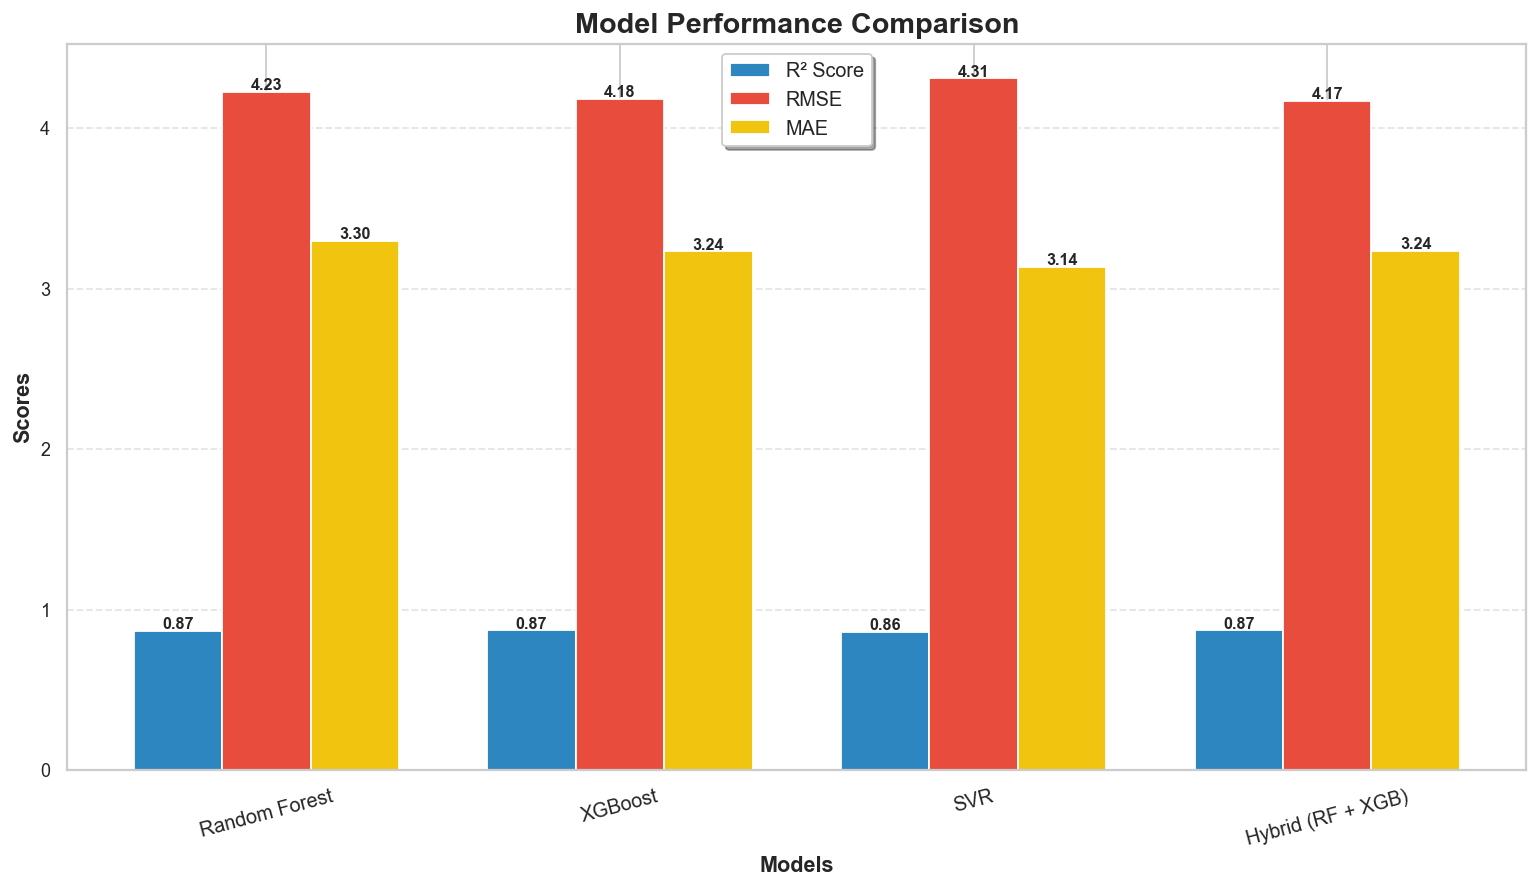

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Improved resolution
plt.figure(figsize=(12,7), dpi=130)

# Clean results dataframe (without pipeline)
results_df = pd.DataFrame(results).T.drop(columns=["pipeline"])
results_df = results_df[["r2", "rmse", "mae"]]

# Styling
sns.set_theme(style="whitegrid")

# Bar settings
bar_width = 0.25
index = np.arange(len(results_df))

# Colors for readability
colors = {
    "r2": "#2E86C1",
    "rmse": "#E74C3C",
    "mae": "#F1C40F"
}

# Plot bars
bars_r2 = plt.bar(index - bar_width, results_df["r2"], color=colors["r2"], width=bar_width, label="R² Score")
bars_rmse = plt.bar(index, results_df["rmse"], color=colors["rmse"], width=bar_width, label="RMSE")
bars_mae = plt.bar(index + bar_width, results_df["mae"], color=colors["mae"], width=bar_width, label="MAE")

# Add value labels on top of bars
for bars in [bars_r2, bars_rmse, bars_mae]:
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.01,
                 f"{height:.2f}", ha='center', fontsize=9, fontweight='bold')

# Formatting
plt.xlabel("Models", fontsize=12, fontweight='bold')
plt.ylabel("Scores", fontsize=12, fontweight='bold')
plt.title("Model Performance Comparison", fontsize=16, fontweight='bold')

plt.xticks(index, results_df.index, rotation=15, fontsize=11)
plt.yticks(fontsize=10)

plt.legend(fontsize=11, frameon=True, shadow=True)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

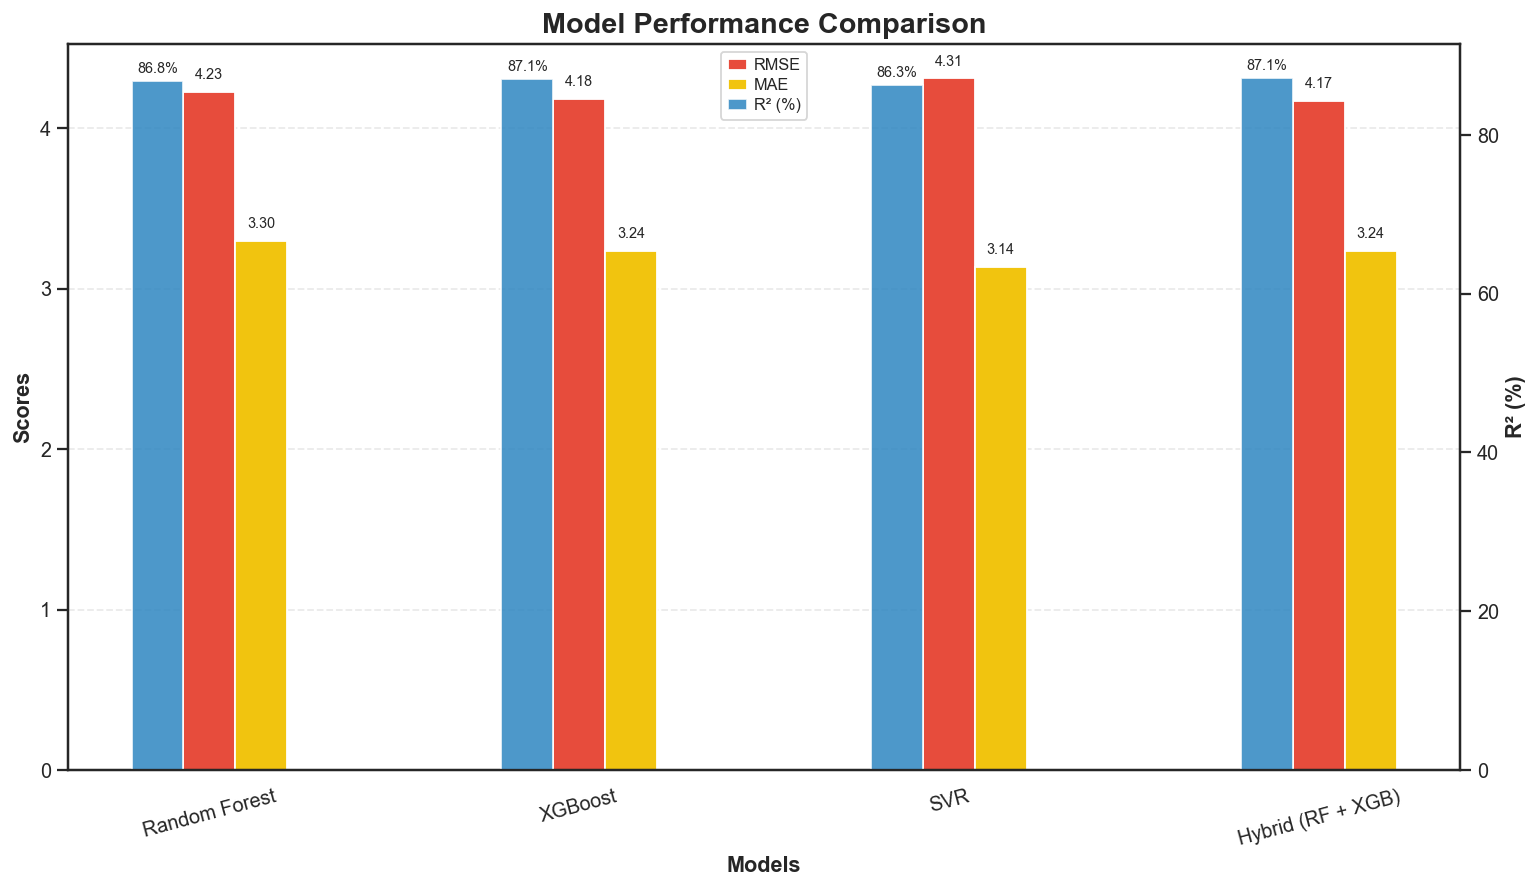

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

# ----------------------------
# Prepare Data
# ----------------------------
results_df = pd.DataFrame(results).T.drop(columns=["pipeline"])
results_df = results_df[["r2", "rmse", "mae"]]

# Convert R² to percentage
results_df["r2_percent"] = results_df["r2"] * 100

# ----------------------------
# Styling
# ----------------------------
sns.set_theme(style="white")

# Bar settings
bar_width = 0.14
index = np.arange(len(results_df))

# Colors
colors = {
    "r2": "#2E86C1",
    "rmse": "#E74C3C",
    "mae": "#F1C40F"
}

# ----------------------------
# Plot
# ----------------------------
fig, ax1 = plt.subplots(figsize=(12,7), dpi=130)
fig.patch.set_facecolor("white")

# Primary axis: RMSE & MAE (Marks)
bars_rmse = ax1.bar(
    index, results_df["rmse"],
    width=bar_width, color=colors["rmse"],
    label="RMSE"
)

bars_mae = ax1.bar(
    index + bar_width, results_df["mae"],
    width=bar_width, color=colors["mae"],
    label="MAE"
)

ax1.set_ylabel("Scores", fontsize=12, fontweight="bold")
ax1.set_xlabel("Models", fontsize=12, fontweight="bold")

# Secondary axis: R² (%)
ax2 = ax1.twinx()
bars_r2 = ax2.bar(
    index - bar_width, results_df["r2_percent"],
    width=bar_width, color=colors["r2"],
    label="R² (%)", alpha=0.85
)

ax2.set_ylabel("R² (%)", fontsize=12, fontweight="bold")

# ----------------------------
# Value Labels
# ----------------------------
for bars in [bars_rmse, bars_mae]:
    for bar in bars:
        h = bar.get_height()
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.08,
            f"{h:.2f}",
            ha="center",
            fontsize=8
        )

for bar in bars_r2:
    h = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        h + 1,
        f"{h:.1f}%",
        ha="center",
        fontsize=8
        )

# ----------------------------
# Axes & Grid
# ----------------------------
ax1.set_xticks(index)
ax1.set_xticklabels(results_df.index, rotation=15, fontsize=11)

ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax2.grid(False)

# ----------------------------
# Title
# ----------------------------
plt.title(
    "Model Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

# ----------------------------
# Compact Legend
# ----------------------------
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    fontsize=9,
    frameon=True,
    borderpad=0.4,
    labelspacing=0.3,
    handlelength=1.2,
    handletextpad=0.4,
    loc="upper center"
)

plt.tight_layout()
plt.show()


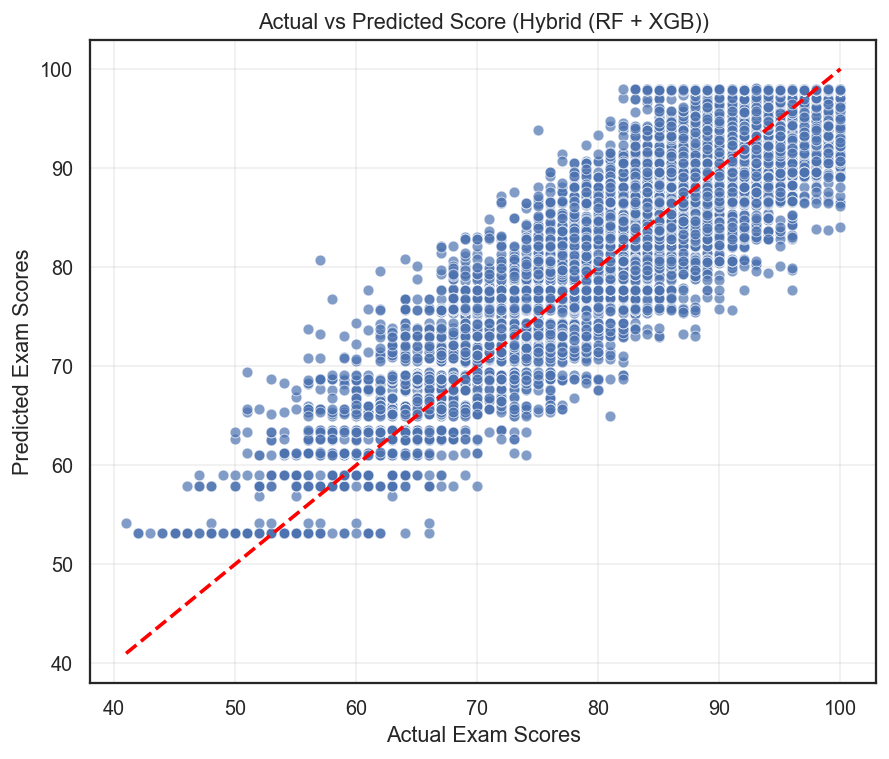

In [20]:
best_model_name = max(results, key=lambda x: results[x]["r2"])
best_pipeline = results[best_model_name]["pipeline"]

best_preds = best_pipeline.predict(X_test)

plt.figure(figsize=(7,6), dpi=130)
sns.scatterplot(x=y_test, y=best_preds, alpha=0.7)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title(f"Actual vs Predicted Score ({best_model_name})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



📉 Residual Analysis → Random Forest


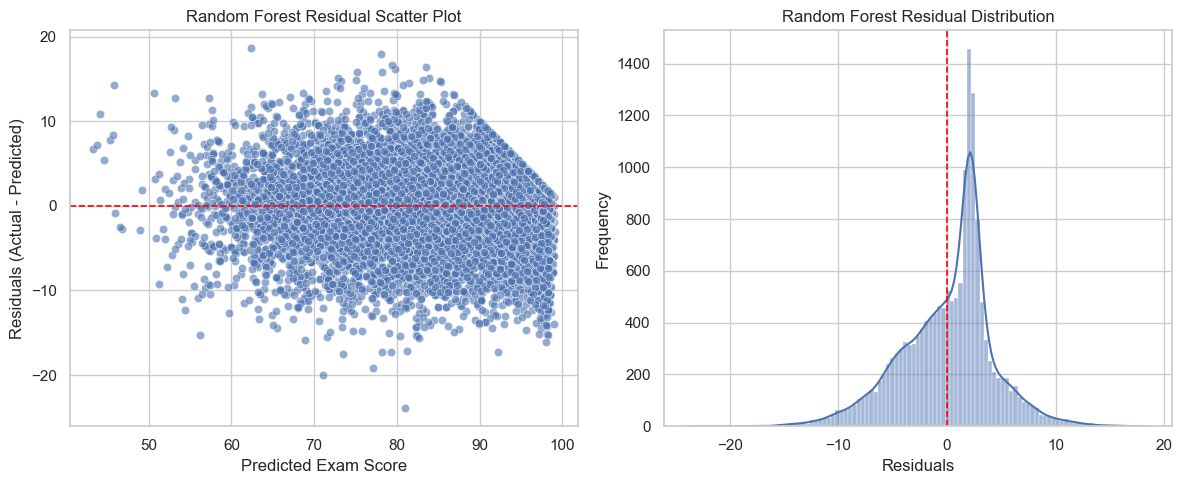


📉 Residual Analysis → XGBoost


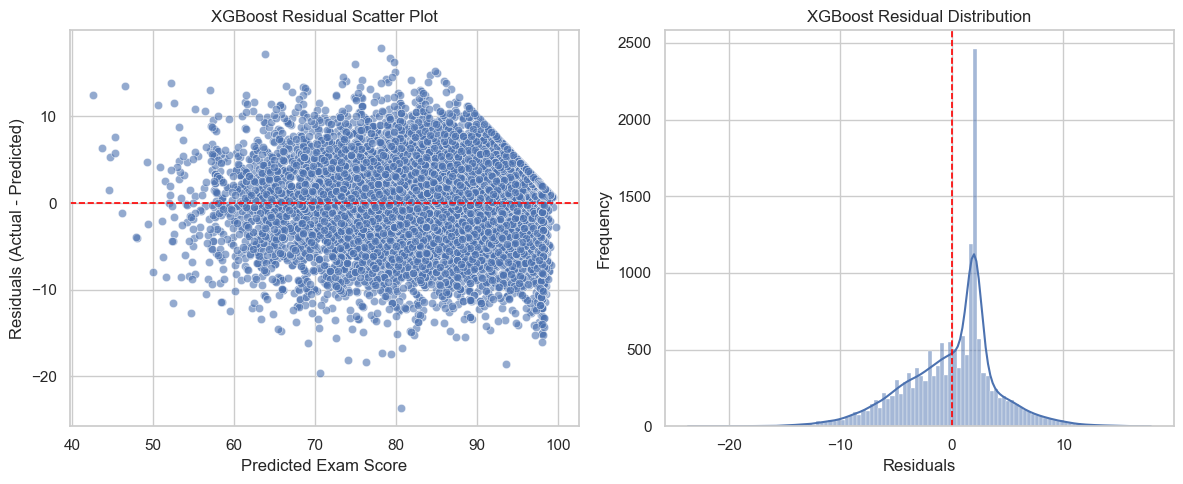


📉 Residual Analysis → SVR


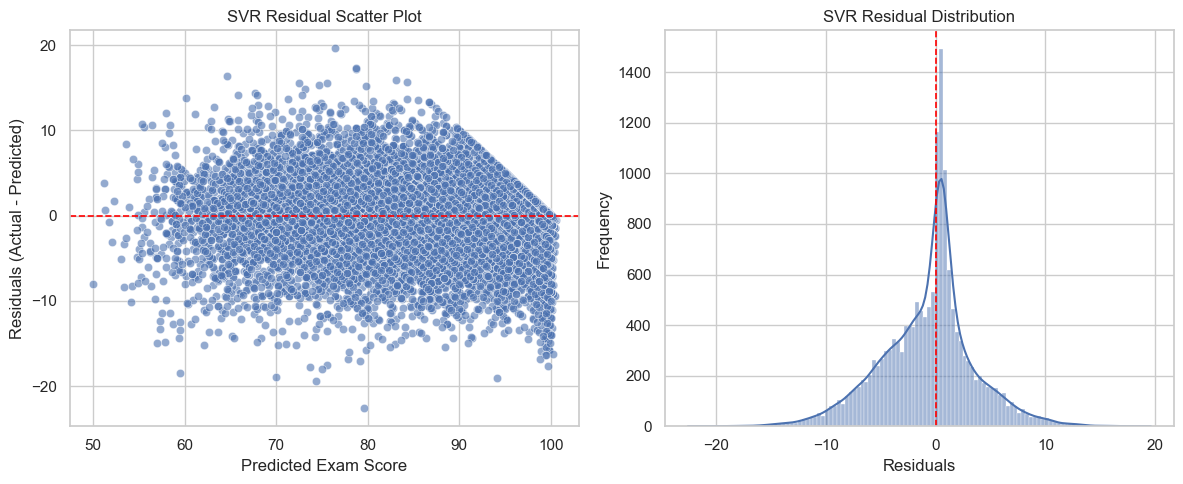


📉 Residual Analysis → Hybrid (RF + XGB)


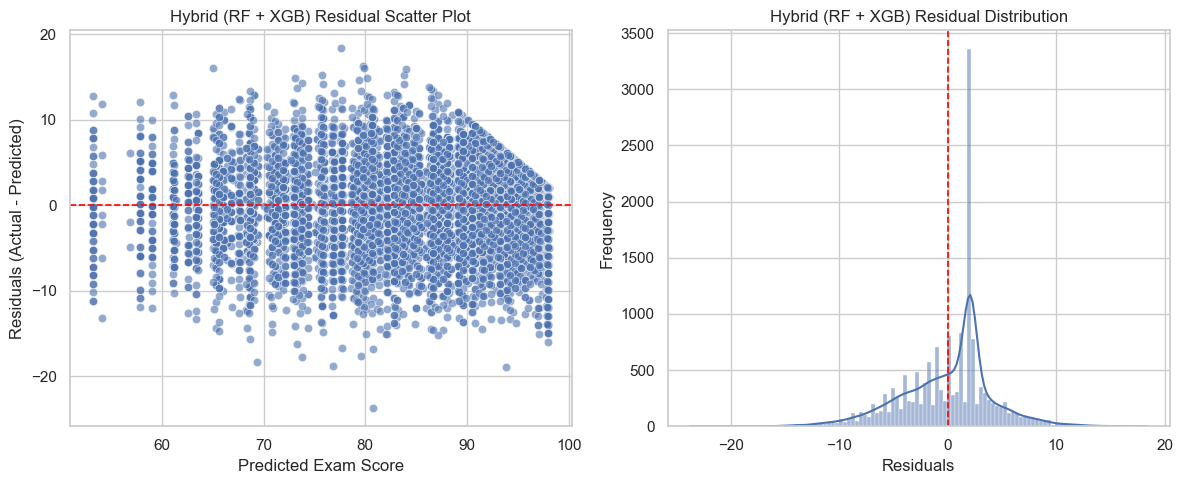

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

def plot_residuals(model_name, y_test, preds):
    residuals = y_test - preds

    plt.figure(figsize=(12,5))

    # Scatter Residual Plot
    plt.subplot(1,2,1)
    sns.scatterplot(x=preds, y=residuals, alpha=0.6)
    plt.axhline(0, color='red', linestyle='--', linewidth=1.2)
    plt.xlabel("Predicted Exam Score")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.title(f"{model_name} Residual Scatter Plot")

    # Distribution Plot
    plt.subplot(1,2,2)
    sns.histplot(residuals, kde=True)
    plt.axvline(0, color='red', linestyle='--', linewidth=1.2)
    plt.xlabel("Residuals")
    plt.ylabel("Frequency")
    plt.title(f"{model_name} Residual Distribution")

    plt.tight_layout()
    plt.show()


# Generate residual plots for all models
for name, model_data in results.items():
    preds = model_data["pipeline"].predict(X_test)
    print(f"\n📉 Residual Analysis → {name}")
    plot_residuals(name, y_test, preds)


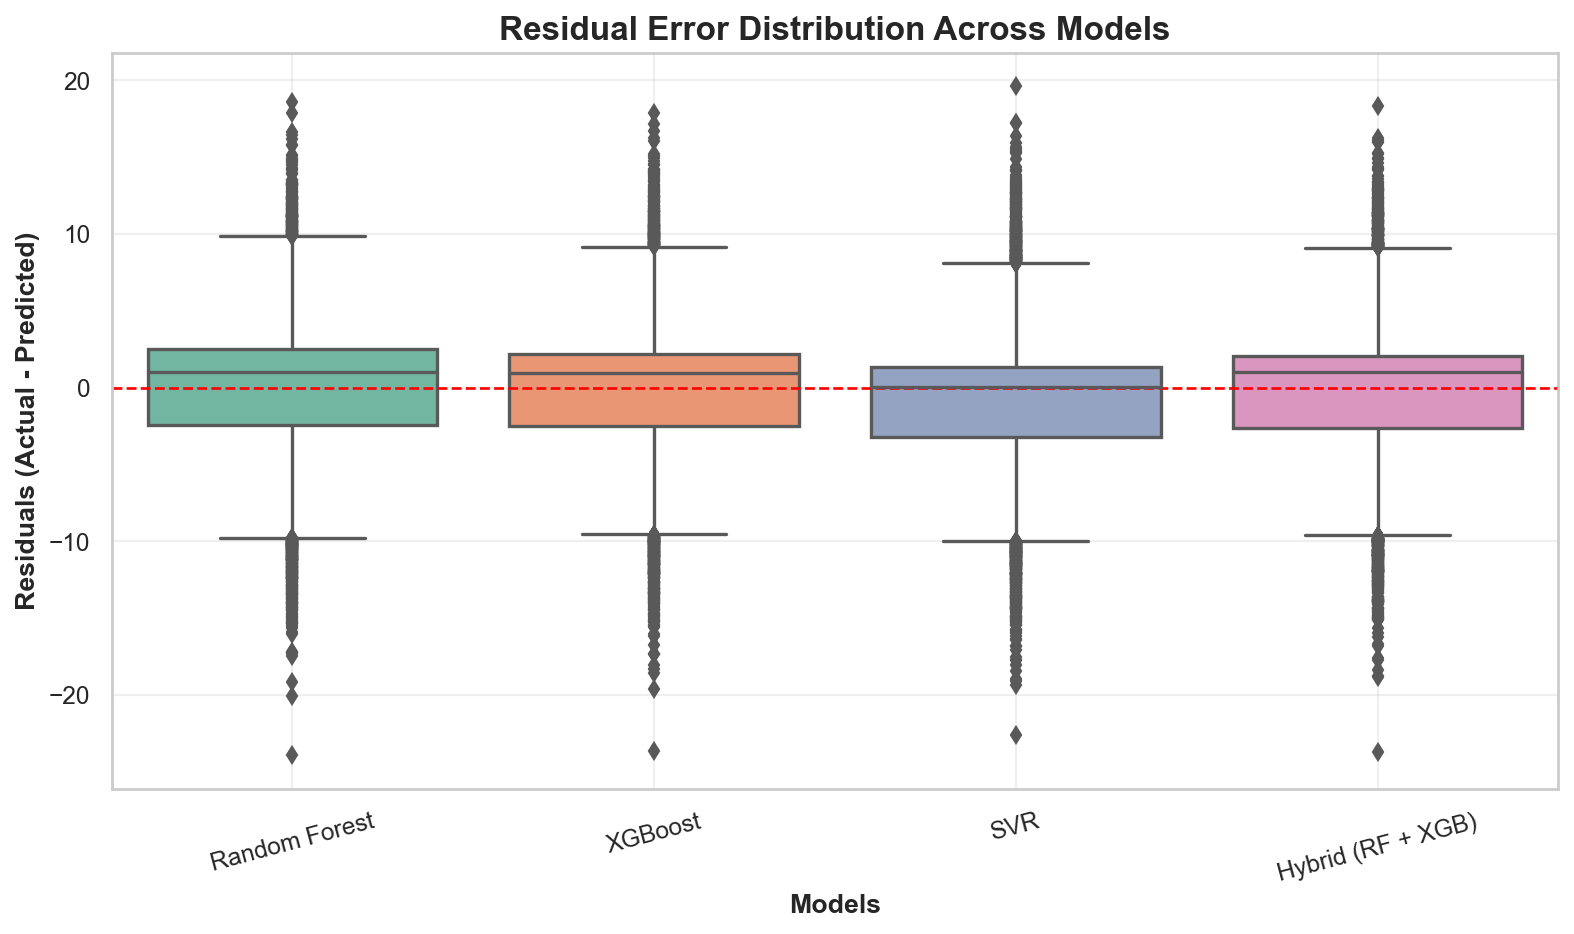

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare residuals for each model
error_data = {}

for name, model_data in results.items():
    preds = model_data["pipeline"].predict(X_test)
    residuals = y_test - preds
    error_data[name] = residuals.values

error_df = pd.DataFrame(error_data)

# Plot
plt.figure(figsize=(10,6), dpi=160)
sns.boxplot(data=error_df, palette="Set2")

plt.axhline(0, color='red', linestyle='--', linewidth=1.2)
plt.title("Residual Error Distribution Across Models", fontsize=15, fontweight="bold")
plt.xlabel("Models", fontsize=12, fontweight="bold")
plt.ylabel("Residuals (Actual - Predicted)", fontsize=12, fontweight="bold")
plt.grid(alpha=0.3)
plt.xticks(rotation=15, fontsize=11)

plt.tight_layout()
plt.show()


In [23]:
best_model_name = max(results, key=lambda x: results[x]["r2"])
best_pipeline = results[best_model_name]["pipeline"]

joblib.dump(best_pipeline, "best_exam_score_model.pkl")

print(f"\n🏆 Best Model: {best_model_name}")
print("✅ Saved as best_exam_score_model.pkl")



🏆 Best Model: Hybrid (RF + XGB)
✅ Saved as best_exam_score_model.pkl


In [24]:
user_input = {
    # Raw Academic & Lifestyle Inputs
    "study_hours_per_day": 6,
    "sleep_hours": 7,
    "social_media_hours": 2,
    "netflix_hours": 1,
    "screen_time": 3,
    "attendance_percentage": 88,
    "previous_gpa": 8.1,
    "time_management_score": 7,
    "motivation_level": 8,

    # Psychological Inputs
    "stress_level": 3,
    "exam_anxiety_score": 4,

    # Selected Categorical Inputs
    "major": "Computer Science",
    "study_environment": "Quiet Room",
    "parental_education_level": "Bachelor",
    "diet_quality": "Good"
}


In [25]:
def prepare_user_input(user_input: dict):
    data = user_input.copy()

    # Engineered features
    data["screen_time_total"] = (
        data["social_media_hours"] +
        data["netflix_hours"] +
        data["screen_time"]
    )

    data["study_sleep_ratio"] = (
        data["study_hours_per_day"] / data["sleep_hours"]
    )

    data["stress_anxiety"] = (
        data["stress_level"] + data["exam_anxiety_score"]
    )

    # Final features expected by model
    final_data = {
        "previous_gpa": data["previous_gpa"],
        "motivation_level": data["motivation_level"],
        "stress_anxiety": data["stress_anxiety"],
        "study_sleep_ratio": data["study_sleep_ratio"],
        "screen_time_total": data["screen_time_total"],
        "time_management_score": data["time_management_score"],
        "attendance_percentage": data["attendance_percentage"],

        # Updated categorical features
        "major": data["major"],
        "study_environment": data["study_environment"],
        "parental_education_level": data["parental_education_level"],
        "diet_quality": data["diet_quality"]
    }

    return pd.DataFrame([final_data])


In [26]:
# load saved model
best_model = joblib.load("best_exam_score_model.pkl")

# prepare input
user_df = prepare_user_input(user_input)

# predict
predicted_score = best_model.predict(user_df)

print(f"🎯 Predicted Exam Score: {predicted_score[0]:.2f}")


🎯 Predicted Exam Score: 97.92
